Saving windSpeedData.txt to windSpeedData (1).txt
CHARGEMENT ET PRÉPARATION DES DONNÉES
✓ Données chargées: 52559 valeurs
  Vitesse min: 0.020 m/s, max: 101.400 m/s
  Moyenne: 6.031 m/s, Écart-type: 4.795 m/s

✓ Séquences créées:
  Nombre d'exemples: 52549
  Forme X: (52549, 10) (échantillons × features)
  Forme y: (52549, 1)

✓ Division Train/Test:
  Données d'entraînement: 42039 (80%)
  Données de test: 10510 (20%)

CONFIGURATION ET ENTRAÎNEMENT DU RÉSEAU ELM
✓ Paramètres ELM:
  Neurones cachés: 100
  Fonction d'activation: tanh
  Temps d'entraînement: 0.8908 secondes

PRÉDICTIONS ET ÉVALUATION

Train Set - Métriques:
  RMSE: 2.1607 m/s
  MAE:  0.8855 m/s
  MAPE: 17.85%
  R²:   0.8138

Test Set - Métriques:
  RMSE: 0.8607 m/s
  MAE:  0.6415 m/s
  MAPE: 134.08%
  R²:   0.8011

GÉNÉRATION DES GRAPHIQUES
✓ Graphiques ELM sauvegardés: ELM_evaluation.png
✓ Graphiques des erreurs sauvegardés: ELM_errors.png

RÉSUMÉ DES MÉTRIQUES - ELM
  Métrique     Train       Test
RMSE (m/s)  2.160750   

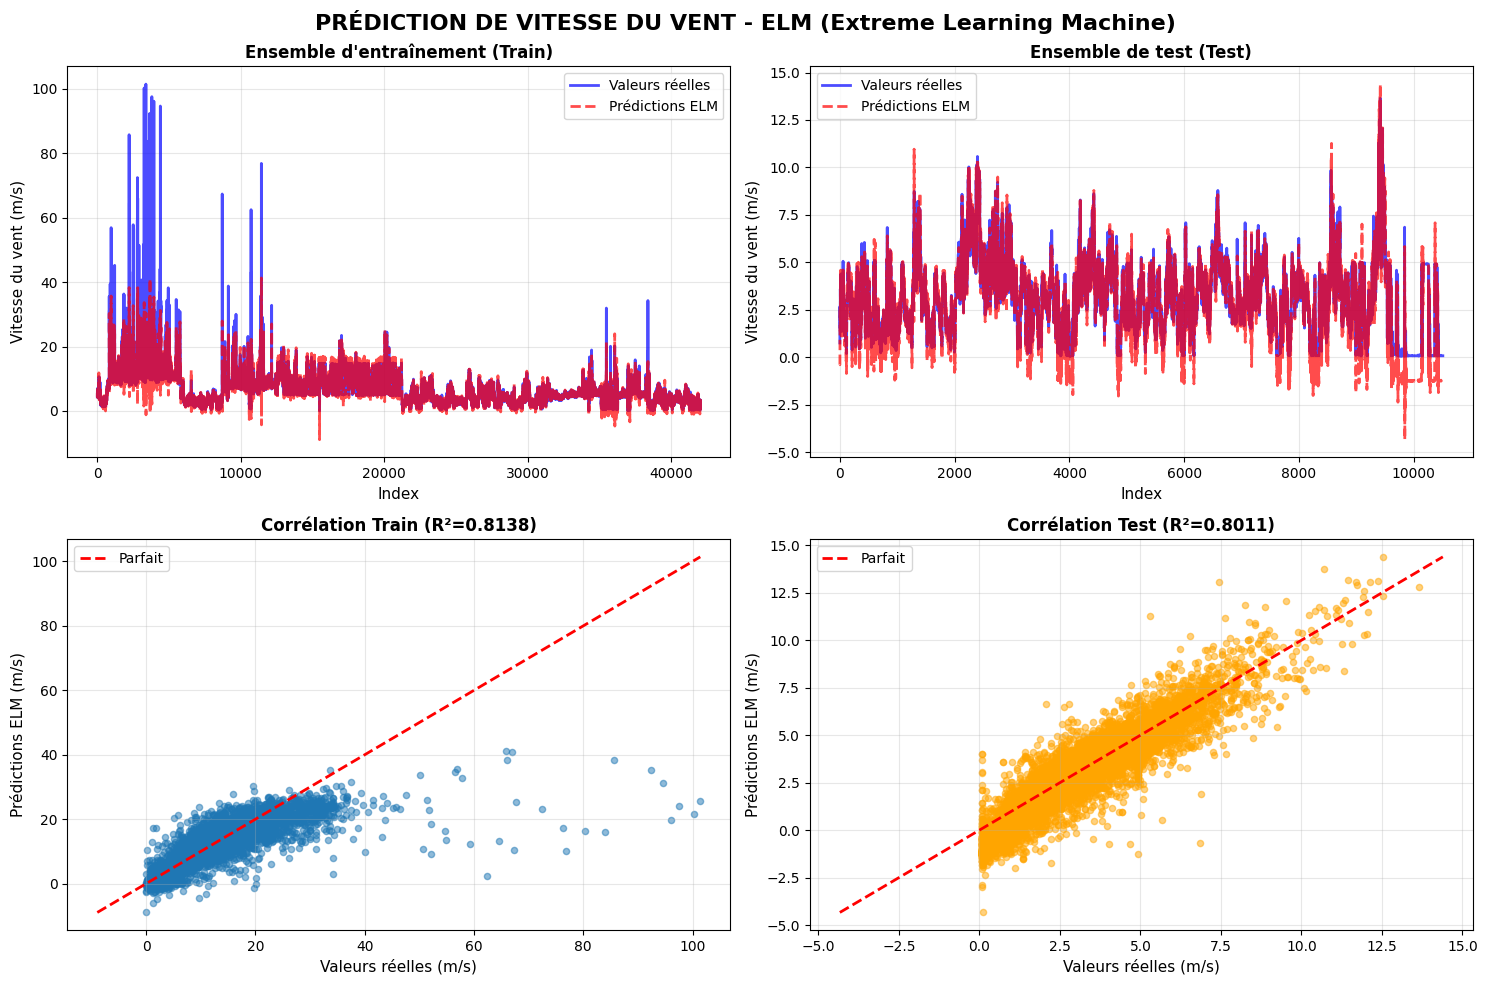

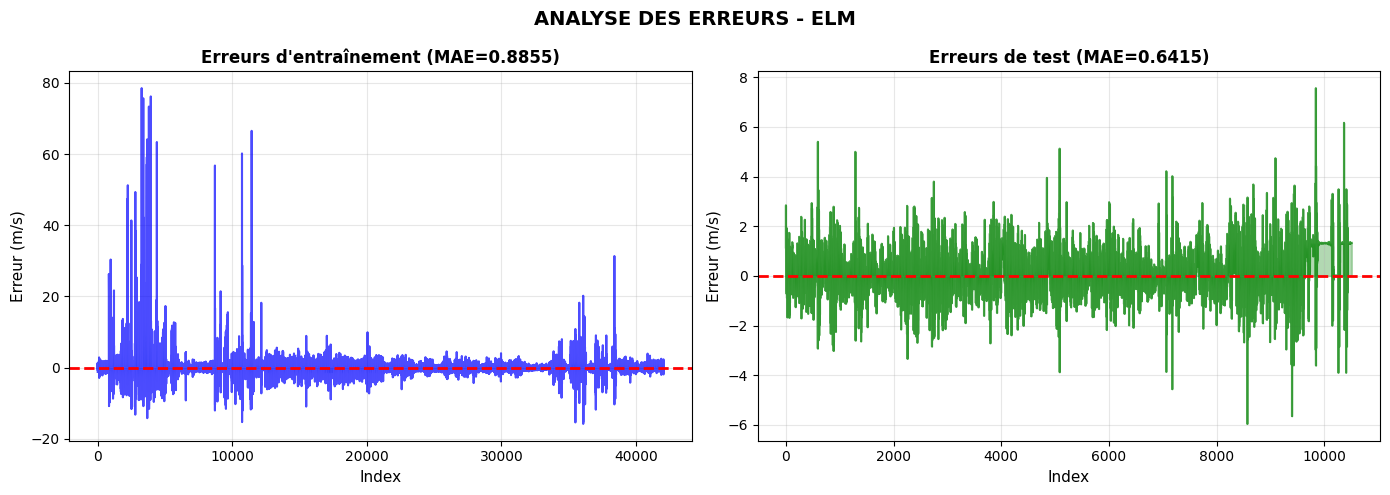

In [6]:
"""
PRÉDICTION DE LA VITESSE DU VENT - EXTREME LEARNING MACHINE (ELM)
==================================================================
Régression ELM pour prédire la vitesse du vent à l'instant 11
basée sur les 10 valeurs passées (instants 1 à 10)
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import random as rd
import time
import warnings
warnings.filterwarnings('ignore')

from google.colab import files
uploaded = files.upload()

# ============================================================================
# 1. CHARGEMENT ET PRÉPARATION DES DONNÉES
# ============================================================================

print("="*70)
print("CHARGEMENT ET PRÉPARATION DES DONNÉES")
print("="*70)

# Charger les données
data = np.loadtxt('windSpeedData.txt')
print(f"✓ Données chargées: {len(data)} valeurs")
print(f"  Vitesse min: {data.min():.3f} m/s, max: {data.max():.3f} m/s")
print(f"  Moyenne: {data.mean():.3f} m/s, Écart-type: {data.std():.3f} m/s")

# Créer les séquences (fenêtre glissante)
sequence_length = 10  # 10 valeurs passées
X = []
y = []

for i in range(len(data) - sequence_length):
    X.append(data[i:i + sequence_length])
    y.append(data[i + sequence_length])

X = np.array(X)
y = np.array(y).reshape(-1, 1)

print(f"\n✓ Séquences créées:")
print(f"  Nombre d'exemples: {len(X)}")
print(f"  Forme X: {X.shape} (échantillons × features)")
print(f"  Forme y: {y.shape}")

# Normalisation
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_scaled = scaler_X.fit_transform(X)
y_scaled = scaler_y.fit_transform(y)

# Division train/test (80/20)
split_idx = int(0.8 * len(X_scaled))
X_train = X_scaled[:split_idx]
X_test = X_scaled[split_idx:]
y_train = y_scaled[:split_idx]
y_test = y_scaled[split_idx:]

print(f"\n✓ Division Train/Test:")
print(f"  Données d'entraînement: {len(X_train)} (80%)")
print(f"  Données de test: {len(X_test)} (20%)")

# ============================================================================
# 2. IMPLÉMENTATION DU RÉSEAU ELM
# ============================================================================

print("\n" + "="*70)
print("CONFIGURATION ET ENTRAÎNEMENT DU RÉSEAU ELM")
print("="*70)

class ELMRegressor:
    def __init__(self, n_hidden=100, random_state=42):
        """
        Initialise le réseau ELM

        Parameters:
        -----------
        n_hidden : int
            Nombre de neurones cachés
        random_state : int
            Graine pour reproductibilité
        """
        self.n_hidden = n_hidden
        self.random_state = random_state
        self.W_input = None
        self.b_hidden = None
        self.beta = None

    def fit(self, X, y):
        """
        Entraîne le réseau ELM

        Parameters:
        -----------
        X : array-like, shape (n_samples, n_features)
            Données d'entraînement
        y : array-like, shape (n_samples, 1)
            Cibles
        """
        np.random.seed(self.random_state)
        rd.seed(self.random_state)

        n_features = X.shape[1]
        n_samples = X.shape[0]

        # Initialisation aléatoire des poids et biais
        self.W_input = np.random.uniform(-1, 1, (n_features, self.n_hidden))
        self.b_hidden = np.random.uniform(-1, 1, (1, self.n_hidden))

        # Calcul de la matrice H (activations des couches cachées)
        # Fonction d'activation: tanh
        H = np.tanh(np.dot(X, self.W_input) + self.b_hidden)

        # Calcul de la pseudo-inverse et des poids de sortie
        H_pinv = np.linalg.pinv(H)
        self.beta = np.dot(H_pinv, y)

        return self

    def predict(self, X):
        """
        Effectue les prédictions

        Parameters:
        -----------
        X : array-like, shape (n_samples, n_features)
            Données pour les prédictions

        Returns:
        --------
        y_pred : array, shape (n_samples, 1)
            Prédictions
        """
        H = np.tanh(np.dot(X, self.W_input) + self.b_hidden)
        return np.dot(H, self.beta)

# Configuration et entraînement
n_hidden_neurons = 100
start_time = time.time()

elm = ELMRegressor(n_hidden=n_hidden_neurons, random_state=42)
elm.fit(X_train, y_train)

train_time = time.time() - start_time

print(f"✓ Paramètres ELM:")
print(f"  Neurones cachés: {n_hidden_neurons}")
print(f"  Fonction d'activation: tanh")
print(f"  Temps d'entraînement: {train_time:.4f} secondes")

# ============================================================================
# 3. PRÉDICTIONS
# ============================================================================

print("\n" + "="*70)
print("PRÉDICTIONS ET ÉVALUATION")
print("="*70)

# Prédictions
y_train_pred = elm.predict(X_train)
y_test_pred = elm.predict(X_test)

# Dénormalisation pour évaluation
y_train_denorm = scaler_y.inverse_transform(y_train)
y_test_denorm = scaler_y.inverse_transform(y_test)
y_train_pred_denorm = scaler_y.inverse_transform(y_train_pred)
y_test_pred_denorm = scaler_y.inverse_transform(y_test_pred)

# ============================================================================
# 4. MÉTRIQUES D'ÉVALUATION
# ============================================================================

def calculate_metrics(y_true, y_pred, set_name="Test"):
    """Calcule les métriques de performance"""
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    # MAPE (Mean Absolute Percentage Error)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    print(f"\n{set_name} Set - Métriques:")
    print(f"  RMSE: {rmse:.4f} m/s")
    print(f"  MAE:  {mae:.4f} m/s")
    print(f"  MAPE: {mape:.2f}%")
    print(f"  R²:   {r2:.4f}")

    return {'RMSE': rmse, 'MAE': mae, 'MAPE': mape, 'R²': r2}

metrics_train = calculate_metrics(y_train_denorm, y_train_pred_denorm, "Train")
metrics_test = calculate_metrics(y_test_denorm, y_test_pred_denorm, "Test")

# ============================================================================
# 5. VISUALISATIONS
# ============================================================================

print("\n" + "="*70)
print("GÉNÉRATION DES GRAPHIQUES")
print("="*70)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('PRÉDICTION DE VITESSE DU VENT - ELM (Extreme Learning Machine)',
             fontsize=16, fontweight='bold')

# Graphique 1: Prédictions vs Valeurs réelles (Train)
ax = axes[0, 0]
ax.plot(y_train_denorm, 'b-', label='Valeurs réelles', linewidth=2, alpha=0.7)
ax.plot(y_train_pred_denorm, 'r--', label='Prédictions ELM', linewidth=2, alpha=0.7)
ax.set_xlabel('Index', fontsize=11)
ax.set_ylabel('Vitesse du vent (m/s)', fontsize=11)
ax.set_title('Ensemble d\'entraînement (Train)', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

# Graphique 2: Prédictions vs Valeurs réelles (Test)
ax = axes[0, 1]
ax.plot(y_test_denorm, 'b-', label='Valeurs réelles', linewidth=2, alpha=0.7)
ax.plot(y_test_pred_denorm, 'r--', label='Prédictions ELM', linewidth=2, alpha=0.7)
ax.set_xlabel('Index', fontsize=11)
ax.set_ylabel('Vitesse du vent (m/s)', fontsize=11)
ax.set_title('Ensemble de test (Test)', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

# Graphique 3: Scatter plot (Train)
ax = axes[1, 0]
ax.scatter(y_train_denorm, y_train_pred_denorm, alpha=0.5, s=20)
min_val = min(y_train_denorm.min(), y_train_pred_denorm.min())
max_val = max(y_train_denorm.max(), y_train_pred_denorm.max())
ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Parfait')
ax.set_xlabel('Valeurs réelles (m/s)', fontsize=11)
ax.set_ylabel('Prédictions ELM (m/s)', fontsize=11)
ax.set_title(f'Corrélation Train (R²={metrics_train["R²"]:.4f})', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

# Graphique 4: Scatter plot (Test)
ax = axes[1, 1]
ax.scatter(y_test_denorm, y_test_pred_denorm, alpha=0.5, s=20, color='orange')
min_val = min(y_test_denorm.min(), y_test_pred_denorm.min())
max_val = max(y_test_denorm.max(), y_test_pred_denorm.max())
ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Parfait')
ax.set_xlabel('Valeurs réelles (m/s)', fontsize=11)
ax.set_ylabel('Prédictions ELM (m/s)', fontsize=11)
ax.set_title(f'Corrélation Test (R²={metrics_test["R²"]:.4f})', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('ELM_evaluation.png', dpi=300, bbox_inches='tight')
print("✓ Graphiques ELM sauvegardés: ELM_evaluation.png")

# Graphique des erreurs
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('ANALYSE DES ERREURS - ELM', fontsize=14, fontweight='bold')

# Erreurs Train
errors_train = y_train_denorm - y_train_pred_denorm
ax = axes[0]
ax.plot(errors_train, 'b-', alpha=0.7, linewidth=1.5)
ax.axhline(y=0, color='r', linestyle='--', linewidth=2)
ax.fill_between(range(len(errors_train)), errors_train.flatten(), alpha=0.3)
ax.set_xlabel('Index', fontsize=11)
ax.set_ylabel('Erreur (m/s)', fontsize=11)
ax.set_title(f'Erreurs d\'entraînement (MAE={metrics_train["MAE"]:.4f})',
             fontsize=12, fontweight='bold')
ax.grid(True, alpha=0.3)

# Erreurs Test
errors_test = y_test_denorm - y_test_pred_denorm
ax = axes[1]
ax.plot(errors_test, 'g-', alpha=0.7, linewidth=1.5)
ax.axhline(y=0, color='r', linestyle='--', linewidth=2)
ax.fill_between(range(len(errors_test)), errors_test.flatten(), alpha=0.3, color='green')
ax.set_xlabel('Index', fontsize=11)
ax.set_ylabel('Erreur (m/s)', fontsize=11)
ax.set_title(f'Erreurs de test (MAE={metrics_test["MAE"]:.4f})',
             fontsize=12, fontweight='bold')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('ELM_errors.png', dpi=300, bbox_inches='tight')
print("✓ Graphiques des erreurs sauvegardés: ELM_errors.png")

# Sauvegarder les métriques
metrics_df = pd.DataFrame({
    'Métrique': ['RMSE (m/s)', 'MAE (m/s)', 'MAPE (%)', 'R² Score'],
    'Train': [metrics_train['RMSE'], metrics_train['MAE'],
              metrics_train['MAPE'], metrics_train['R²']],
    'Test': [metrics_test['RMSE'], metrics_test['MAE'],
             metrics_test['MAPE'], metrics_test['R²']]
})

print("\n" + "="*70)
print("RÉSUMÉ DES MÉTRIQUES - ELM")
print("="*70)
print(metrics_df.to_string(index=False))

# Sauvegarder dans un CSV
metrics_df.to_csv('ELM_metrics.csv', index=False)
print("\n✓ Métriques sauvegardées: ELM_metrics.csv")

print("\n" + "="*70)
print("✓ ELM TERMINÉ AVEC SUCCÈS")
print("="*70)


In [20]:
# ============================================================================
# AFFICHAGE DE LA PRÉDICTION À L'INSTANT 11 - MODÈLE ELM
# ============================================================================

# 1. Sélection de la première séquence (X_test contient les instants 1 à 10)
X_11_elm = X_test[0:1]

# 2. Prédiction brute par le modèle ELM
y_11_pred_scaled = elm.predict(X_11_elm)

# 3. Dé-normalisation (retour aux m/s)
X_11_denorm = scaler_X.inverse_transform(X_11_elm).flatten()
y_11_pred_raw = scaler_y.inverse_transform(y_11_pred_scaled.reshape(-1, 1))[0][0]

# 4. Application de la contrainte physique (uniquement valeur positive)
y_11_pred_final = max(0, y_11_pred_raw)

# 5. Valeur réelle pour comparaison
y_11_real = y_test_denorm[0][0]

# --- AFFICHAGE FINAL ---
print("="*60)
print("DÉTAIL DE LA PRÉDICTION À L'INSTANT 11 (ELM)")
print("="*60)
print("Série temporelle d'entrée (Instants 1 à 10) :")
for i, val in enumerate(X_11_denorm, 1):
    print(f"  Instant {i:2d} : {val:.3f} m/s")

print("-" * 30)
print(f"PRÉDICTION DU MODÈLE (Instant 11) : {y_11_pred_final:.3f} m/s")
print(f"VALEUR RÉELLE OBSERVÉE (Instant 11) : {y_11_real:.3f} m/s")
print(f"ERREUR COMMISE                  : {abs(y_11_pred_final - y_11_real):.3f} m/s")
print("="*60)

DÉTAIL DE LA PRÉDICTION À L'INSTANT 11 (ELM)
Série temporelle d'entrée (Instants 1 à 10) :
  Instant  1 : 2.807 m/s
  Instant  2 : 2.092 m/s
  Instant  3 : 1.182 m/s
  Instant  4 : 1.252 m/s
  Instant  5 : 3.391 m/s
  Instant  6 : 3.172 m/s
  Instant  7 : 1.473 m/s
  Instant  8 : 0.847 m/s
  Instant  9 : 1.031 m/s
  Instant 10 : 0.612 m/s
------------------------------
PRÉDICTION DU MODÈLE (Instant 11) : 0.000 m/s
VALEUR RÉELLE OBSERVÉE (Instant 11) : 0.759 m/s
ERREUR COMMISE                  : 0.759 m/s


Saving windSpeedData.txt to windSpeedData (3).txt
CHARGEMENT ET PRÉPARATION DES DONNÉES
Fichier utilisé: windSpeedData (2).txt
✓ Données chargées: 52559 valeurs
  Vitesse min: 0.020 m/s, max: 101.400 m/s
  Moyenne: 6.031 m/s, Écart-type: 4.795 m/s

✓ Séquences créées:
  Nombre d'exemples: 52549
  Forme X: (52549, 10) (échantillons × features)
  Forme y: (52549, 1)

✓ Division Train/Test:
  Données d'entraînement: 42039 (80%)
  Données de test: 10510 (20%)

CONFIGURATION ET ENTRAÎNEMENT DU MLPRegressor
✓ Paramètres MLPRegressor:
  Architectures: (100, 50)
  Activation: relu
  Solveur: adam
  Learning rate initial: 0.001
  Itérations max: 2000
  Temps d'entraînement: 30.3687 secondes
  Itérations effectuées: 58
  Loss final: 0.063595

PRÉDICTIONS ET ÉVALUATION

Train Set - Métriques:
  RMSE: 1.8586 m/s
  MAE:  0.6854 m/s
  MAPE: 13.75%
  R²:   0.8622

Test Set - Métriques:
  RMSE: 0.6122 m/s
  MAE:  0.4314 m/s
  MAPE: 47.84%
  R²:   0.8994

GÉNÉRATION DES GRAPHIQUES


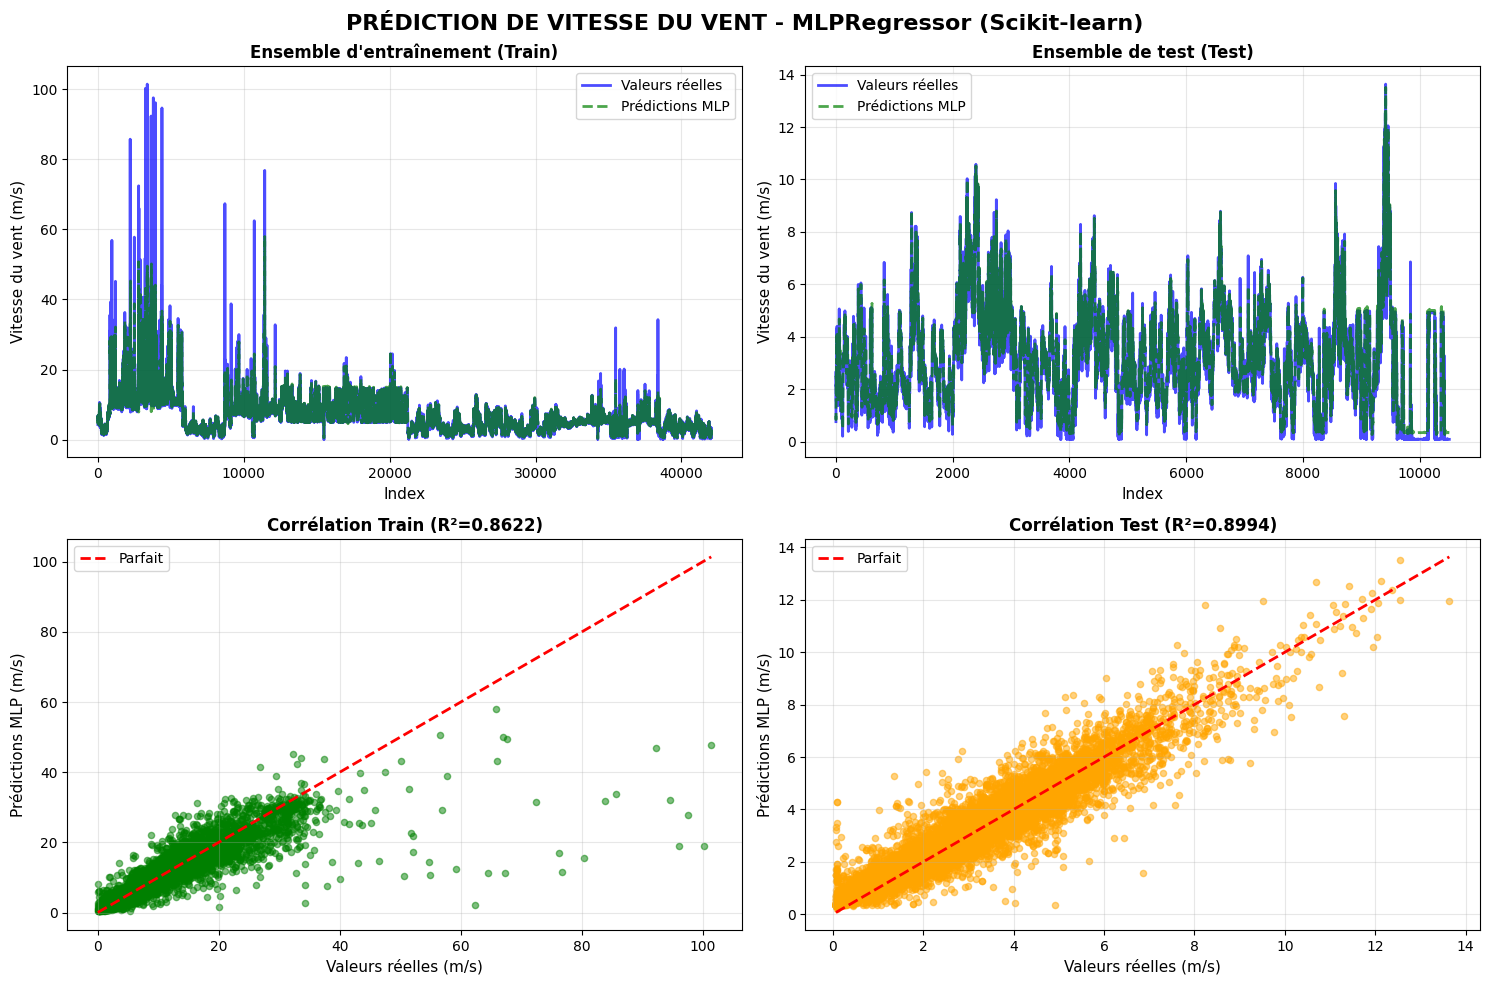

✓ Graphiques générés

RÉSUMÉ DES MÉTRIQUES - MLPRegressor
  Métrique     Train      Test
RMSE (m/s)  1.858591  0.612161
 MAE (m/s)  0.685374  0.431437
  MAPE (%) 13.745152 47.840289
  R² Score  0.862231  0.899366

✓ MLPRegressor TERMINÉ AVEC SUCCÈS


In [9]:
"""
PRÉDICTION DE LA VITESSE DU VENT - MLP REGRESSOR
==================================================
Version adaptée pour Jupyter local - Régression MLPRegressor
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import time
import warnings
import os
warnings.filterwarnings('ignore')

from google.colab import files
uploaded = files.upload()
# ============================================================================
# 1. CHARGEMENT ET PRÉPARATION DES DONNÉES
# ============================================================================

print("="*70)
print("CHARGEMENT ET PRÉPARATION DES DONNÉES")
print("="*70)

import os

# récupérer automatiquement le bon nom de fichier uploadé
files_list = os.listdir()

txt_files = [f for f in files_list if f.endswith('.txt')]

if len(txt_files) == 0:
    raise FileNotFoundError("Aucun fichier .txt trouvé")

file_path = txt_files[0]  # prend le premier fichier txt

print(f"Fichier utilisé: {file_path}")

data = np.loadtxt(file_path)
print(f"✓ Données chargées: {len(data)} valeurs")
print(f"  Vitesse min: {data.min():.3f} m/s, max: {data.max():.3f} m/s")
print(f"  Moyenne: {data.mean():.3f} m/s, Écart-type: {data.std():.3f} m/s")

# Créer les séquences (fenêtre glissante)
sequence_length = 10  # 10 valeurs passées
X = []
y = []

for i in range(len(data) - sequence_length):
    X.append(data[i:i + sequence_length])
    y.append(data[i + sequence_length])

X = np.array(X)
y = np.array(y).reshape(-1, 1)

print(f"\n✓ Séquences créées:")
print(f"  Nombre d'exemples: {len(X)}")
print(f"  Forme X: {X.shape} (échantillons × features)")
print(f"  Forme y: {y.shape}")

# Normalisation
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_scaled = scaler_X.fit_transform(X)
y_scaled = scaler_y.fit_transform(y).ravel()  # MLP préfère 1D pour y

# Division train/test (80/20)
split_idx = int(0.8 * len(X_scaled))
X_train = X_scaled[:split_idx]
X_test = X_scaled[split_idx:]
y_train = y_scaled[:split_idx]
y_test = y_scaled[split_idx:]

print(f"\n✓ Division Train/Test:")
print(f"  Données d'entraînement: {len(X_train)} (80%)")
print(f"  Données de test: {len(X_test)} (20%)")

# ============================================================================
# 2. CONFIGURATION ET ENTRAÎNEMENT DU MLPRegressor
# ============================================================================

print("\n" + "="*70)
print("CONFIGURATION ET ENTRAÎNEMENT DU MLPRegressor")
print("="*70)

# Configuration du MLPRegressor
hidden_layer_sizes = (100, 50)  # Deux couches: 100 et 50 neurones
learning_rate_init = 0.001
max_iterations = 2000
random_state = 42

print(f"✓ Paramètres MLPRegressor:")
print(f"  Architectures: {hidden_layer_sizes}")
print(f"  Activation: relu")
print(f"  Solveur: adam")
print(f"  Learning rate initial: {learning_rate_init}")
print(f"  Itérations max: {max_iterations}")

start_time = time.time()

mlp = MLPRegressor(
    hidden_layer_sizes=hidden_layer_sizes,
    activation='relu',
    solver='adam',
    learning_rate_init=learning_rate_init,
    max_iter=max_iterations,
    random_state=random_state,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=50,
    verbose=False
)

mlp.fit(X_train, y_train)
train_time = time.time() - start_time

print(f"  Temps d'entraînement: {train_time:.4f} secondes")
print(f"  Itérations effectuées: {mlp.n_iter_}")
print(f"  Loss final: {mlp.loss_:.6f}")

# ============================================================================
# 3. PRÉDICTIONS
# ============================================================================

print("\n" + "="*70)
print("PRÉDICTIONS ET ÉVALUATION")
print("="*70)

# Prédictions
y_train_pred = mlp.predict(X_train)
y_test_pred = mlp.predict(X_test)

# Dénormalisation pour évaluation
y_train_denorm = scaler_y.inverse_transform(y_train.reshape(-1, 1))
y_test_denorm = scaler_y.inverse_transform(y_test.reshape(-1, 1))
y_train_pred_denorm = scaler_y.inverse_transform(y_train_pred.reshape(-1, 1))
y_test_pred_denorm = scaler_y.inverse_transform(y_test_pred.reshape(-1, 1))

# ============================================================================
# 4. MÉTRIQUES D'ÉVALUATION
# ============================================================================

def calculate_metrics(y_true, y_pred, set_name="Test"):
    """Calcule les métriques de performance"""
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    print(f"\n{set_name} Set - Métriques:")
    print(f"  RMSE: {rmse:.4f} m/s")
    print(f"  MAE:  {mae:.4f} m/s")
    print(f"  MAPE: {mape:.2f}%")
    print(f"  R²:   {r2:.4f}")

    return {'RMSE': rmse, 'MAE': mae, 'MAPE': mape, 'R²': r2}

metrics_train = calculate_metrics(y_train_denorm, y_train_pred_denorm, "Train")
metrics_test = calculate_metrics(y_test_denorm, y_test_pred_denorm, "Test")

# ============================================================================
# 5. VISUALISATIONS
# ============================================================================

print("\n" + "="*70)
print("GÉNÉRATION DES GRAPHIQUES")
print("="*70)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('PRÉDICTION DE VITESSE DU VENT - MLPRegressor (Scikit-learn)',
             fontsize=16, fontweight='bold')

# Graphique 1: Prédictions vs Valeurs réelles (Train)
ax = axes[0, 0]
ax.plot(y_train_denorm, 'b-', label='Valeurs réelles', linewidth=2, alpha=0.7)
ax.plot(y_train_pred_denorm, 'g--', label='Prédictions MLP', linewidth=2, alpha=0.7)
ax.set_xlabel('Index', fontsize=11)
ax.set_ylabel('Vitesse du vent (m/s)', fontsize=11)
ax.set_title('Ensemble d\'entraînement (Train)', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

# Graphique 2: Prédictions vs Valeurs réelles (Test)
ax = axes[0, 1]
ax.plot(y_test_denorm, 'b-', label='Valeurs réelles', linewidth=2, alpha=0.7)
ax.plot(y_test_pred_denorm, 'g--', label='Prédictions MLP', linewidth=2, alpha=0.7)
ax.set_xlabel('Index', fontsize=11)
ax.set_ylabel('Vitesse du vent (m/s)', fontsize=11)
ax.set_title('Ensemble de test (Test)', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

# Graphique 3: Scatter plot (Train)
ax = axes[1, 0]
ax.scatter(y_train_denorm, y_train_pred_denorm, alpha=0.5, s=20, color='green')
min_val = min(y_train_denorm.min(), y_train_pred_denorm.min())
max_val = max(y_train_denorm.max(), y_train_pred_denorm.max())
ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Parfait')
ax.set_xlabel('Valeurs réelles (m/s)', fontsize=11)
ax.set_ylabel('Prédictions MLP (m/s)', fontsize=11)
ax.set_title(f'Corrélation Train (R²={metrics_train["R²"]:.4f})', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

# Graphique 4: Scatter plot (Test)
ax = axes[1, 1]
ax.scatter(y_test_denorm, y_test_pred_denorm, alpha=0.5, s=20, color='orange')
min_val = min(y_test_denorm.min(), y_test_pred_denorm.min())
max_val = max(y_test_denorm.max(), y_test_pred_denorm.max())
ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Parfait')
ax.set_xlabel('Valeurs réelles (m/s)', fontsize=11)
ax.set_ylabel('Prédictions MLP (m/s)', fontsize=11)
ax.set_title(f'Corrélation Test (R²={metrics_test["R²"]:.4f})', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("✓ Graphiques générés")

# Sauvegarder les métriques
metrics_df = pd.DataFrame({
    'Métrique': ['RMSE (m/s)', 'MAE (m/s)', 'MAPE (%)', 'R² Score'],
    'Train': [metrics_train['RMSE'], metrics_train['MAE'],
              metrics_train['MAPE'], metrics_train['R²']],
    'Test': [metrics_test['RMSE'], metrics_test['MAE'],
             metrics_test['MAPE'], metrics_test['R²']]
})

print("\n" + "="*70)
print("RÉSUMÉ DES MÉTRIQUES - MLPRegressor")
print("="*70)
print(metrics_df.to_string(index=False))

print("\n" + "="*70)
print("✓ MLPRegressor TERMINÉ AVEC SUCCÈS")
print("="*70)


In [16]:
# ============================================================================
# ZOOM SUR LA PRÉDICTION DE L'INSTANT 11
# ============================================================================

# 1. On récupère la première séquence du jeu de test (instants 1 à 10)
X_11 = X_test[0:1] # Format (1, 10)

# 2. Le modèle fait sa prédiction pour l'instant 11
y_11_scaled = mlp.predict(X_11)

# 3. On dé-normalise pour avoir des valeurs en m/s
# Pour l'entrée (les 10 premières valeurs)
X_11_denorm = scaler_X.inverse_transform(X_11).flatten()
# Pour la prédiction (le point 11)
y_11_pred = scaler_y.inverse_transform(y_11_scaled.reshape(-1, 1))[0][0]
# Pour la valeur réelle attendue
y_11_real = y_test_denorm[0][0]

# --- AFFICHAGE ---
print("="*60)
print("DÉTAIL DE LA PRÉDICTION À L'INSTANT 11")
print("="*60)
print(f"Série temporelle d'entrée (Instants 1 à 10) :")
for i, val in enumerate(X_11_denorm, 1):
    print(f"  Instant {i:2d} : {val:.3f} m/s")

print("-" * 30)
print(f"PRÉDICTION DU MODÈLE (Instant 11) : {y_11_pred:.3f} m/s")
print(f"VALEUR RÉELLE OBSERVÉE (Instant 11) : {y_11_real:.3f} m/s")
print(f"ERREUR COMMISE                  : {abs(y_11_pred - y_11_real):.3f} m/s")
print("="*60)

DÉTAIL DE LA PRÉDICTION À L'INSTANT 11
Série temporelle d'entrée (Instants 1 à 10) :
  Instant  1 : 2.807 m/s
  Instant  2 : 2.092 m/s
  Instant  3 : 1.182 m/s
  Instant  4 : 1.252 m/s
  Instant  5 : 3.391 m/s
  Instant  6 : 3.172 m/s
  Instant  7 : 1.473 m/s
  Instant  8 : 0.847 m/s
  Instant  9 : 1.031 m/s
  Instant 10 : 0.612 m/s
------------------------------
PRÉDICTION DU MODÈLE (Instant 11) : 0.981 m/s
VALEUR RÉELLE OBSERVÉE (Instant 11) : 0.759 m/s
ERREUR COMMISE                  : 0.222 m/s


In [11]:
from google.colab import files

def download_file(filename):
    files.download(filename)
# Sauvegarde des graphiques
plt.savefig("MLP_evaluation.png", dpi=300, bbox_inches='tight')
download_file("MLP_evaluation.png")
plt.savefig("MLP_errors.png", dpi=300, bbox_inches='tight')
download_file("MLP_errors.png")
metrics_df.to_csv("MLP_metrics.csv", index=False)
download_file("MLP_metrics.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<Figure size 640x480 with 0 Axes>

COMPARAISON ELM vs MLPRegressor

TABLEAU COMPARATIF - ENSEMBLE D'ENTRAÎNEMENT
  Métrique       ELM       MLP Meilleur
RMSE (m/s)  2.160750  1.858591      MLP
 MAE (m/s)  0.885541  0.685374      MLP
  MAPE (%) 17.852582 13.745152      MLP
  R² Score  0.813794  0.862231      MLP

TABLEAU COMPARATIF - ENSEMBLE DE TEST
  Métrique        ELM       MLP Meilleur
RMSE (m/s)   0.860673  0.612161      MLP
 MAE (m/s)   0.641541  0.431437      MLP
  MAPE (%) 134.080343 47.840289      MLP
  R² Score   0.801075  0.899366      MLP

GÉNÉRATION DES GRAPHIQUES DE COMPARAISON
✓ Graphique de comparaison sauvegardé: Comparison_ELM_MLP.png

ANALYSE ET CONCLUSION

Performance sur l'ensemble d'entraînement:
  ELM - R²: 0.8138, MAE: 0.8855
  MLP - R²: 0.8622, MAE: 0.6854

Performance sur l'ensemble de test:
  ELM - R²: 0.8011, MAE: 0.6415
  MLP - R²: 0.8994, MAE: 0.4314

✓ MEILLEUR MODÈLE: MLPRegressor
  Score: 0.6037 vs 0.1773

  Avantages MLPRegressor:
    - RMSE plus bas: 0.6122 vs 0.8607
    - MAE plus bas

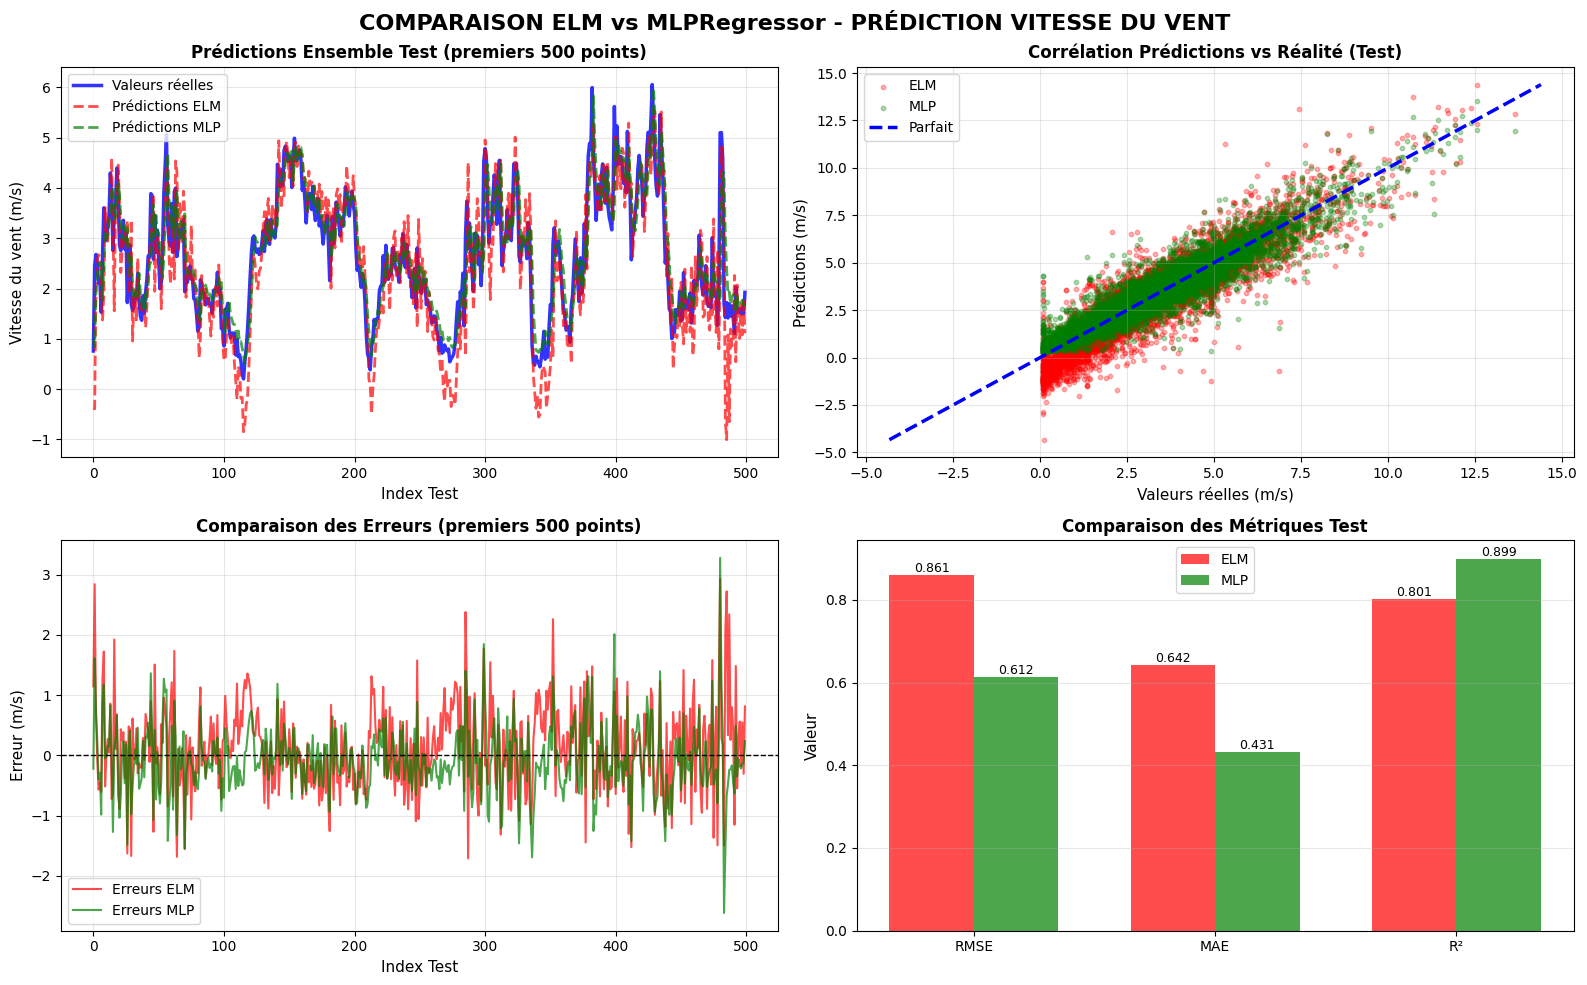

In [12]:
"""
COMPARAISON ELM vs MLPRegressor
================================
Comparaison détaillée des deux modèles de prédiction
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import random as rd
import warnings
warnings.filterwarnings('ignore')

# ============================================================================
# 1. CHARGEMENT ET PRÉPARATION DES DONNÉES
# ============================================================================

print("="*70)
print("COMPARAISON ELM vs MLPRegressor")
print("="*70)

data = np.loadtxt('windSpeedData.txt')
sequence_length = 10
X = []
y = []

for i in range(len(data) - sequence_length):
    X.append(data[i:i + sequence_length])
    y.append(data[i + sequence_length])

X = np.array(X)
y = np.array(y).reshape(-1, 1)

scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_scaled = scaler_X.fit_transform(X)
y_scaled = scaler_y.fit_transform(y)

split_idx = int(0.8 * len(X_scaled))
X_train = X_scaled[:split_idx]
X_test = X_scaled[split_idx:]
y_train = y_scaled[:split_idx]
y_test = y_scaled[split_idx:]

y_train_denorm = scaler_y.inverse_transform(y_train)
y_test_denorm = scaler_y.inverse_transform(y_test)

# ============================================================================
# 2. ELM
# ============================================================================

class ELMRegressor:
    def __init__(self, n_hidden=100, random_state=42):
        self.n_hidden = n_hidden
        self.random_state = random_state
        self.W_input = None
        self.b_hidden = None
        self.beta = None

    def fit(self, X, y):
        np.random.seed(self.random_state)
        rd.seed(self.random_state)
        n_features = X.shape[1]
        self.W_input = np.random.uniform(-1, 1, (n_features, self.n_hidden))
        self.b_hidden = np.random.uniform(-1, 1, (1, self.n_hidden))
        H = np.tanh(np.dot(X, self.W_input) + self.b_hidden)
        H_pinv = np.linalg.pinv(H)
        self.beta = np.dot(H_pinv, y)
        return self

    def predict(self, X):
        H = np.tanh(np.dot(X, self.W_input) + self.b_hidden)
        return np.dot(H, self.beta)

elm = ELMRegressor(n_hidden=100, random_state=42)
elm.fit(X_train, y_train)

y_train_pred_elm = elm.predict(X_train)
y_test_pred_elm = elm.predict(X_test)

y_train_pred_elm_denorm = scaler_y.inverse_transform(y_train_pred_elm)
y_test_pred_elm_denorm = scaler_y.inverse_transform(y_test_pred_elm)

# ============================================================================
# 3. MLP
# ============================================================================

mlp = MLPRegressor(
    hidden_layer_sizes=(100, 50),
    activation='relu',
    solver='adam',
    learning_rate_init=0.001,
    max_iter=2000,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=50,
    verbose=False
)

mlp.fit(X_train, y_train.ravel())

y_train_pred_mlp = mlp.predict(X_train)
y_test_pred_mlp = mlp.predict(X_test)

y_train_pred_mlp_denorm = scaler_y.inverse_transform(y_train_pred_mlp.reshape(-1, 1))
y_test_pred_mlp_denorm = scaler_y.inverse_transform(y_test_pred_mlp.reshape(-1, 1))

# ============================================================================
# 4. CALCUL DES MÉTRIQUES
# ============================================================================

def calculate_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return {'RMSE': rmse, 'MAE': mae, 'MAPE': mape, 'R²': r2}

# ELM Metrics
elm_train_metrics = calculate_metrics(y_train_denorm, y_train_pred_elm_denorm)
elm_test_metrics = calculate_metrics(y_test_denorm, y_test_pred_elm_denorm)

# MLP Metrics
mlp_train_metrics = calculate_metrics(y_train_denorm, y_train_pred_mlp_denorm)
mlp_test_metrics = calculate_metrics(y_test_denorm, y_test_pred_mlp_denorm)

# ============================================================================
# 5. TABLEAU COMPARATIF
# ============================================================================

print("\n" + "="*70)
print("TABLEAU COMPARATIF - ENSEMBLE D'ENTRAÎNEMENT")
print("="*70)

comparison_train = pd.DataFrame({
    'Métrique': ['RMSE (m/s)', 'MAE (m/s)', 'MAPE (%)', 'R² Score'],
    'ELM': [elm_train_metrics['RMSE'], elm_train_metrics['MAE'],
            elm_train_metrics['MAPE'], elm_train_metrics['R²']],
    'MLP': [mlp_train_metrics['RMSE'], mlp_train_metrics['MAE'],
            mlp_train_metrics['MAPE'], mlp_train_metrics['R²']],
    'Meilleur': ['MLP' if mlp_train_metrics['RMSE'] < elm_train_metrics['RMSE'] else 'ELM',
                 'MLP' if mlp_train_metrics['MAE'] < elm_train_metrics['MAE'] else 'ELM',
                 'MLP' if mlp_train_metrics['MAPE'] < elm_train_metrics['MAPE'] else 'ELM',
                 'MLP' if mlp_train_metrics['R²'] > elm_train_metrics['R²'] else 'ELM']
})

print(comparison_train.to_string(index=False))

print("\n" + "="*70)
print("TABLEAU COMPARATIF - ENSEMBLE DE TEST")
print("="*70)

comparison_test = pd.DataFrame({
    'Métrique': ['RMSE (m/s)', 'MAE (m/s)', 'MAPE (%)', 'R² Score'],
    'ELM': [elm_test_metrics['RMSE'], elm_test_metrics['MAE'],
            elm_test_metrics['MAPE'], elm_test_metrics['R²']],
    'MLP': [mlp_test_metrics['RMSE'], mlp_test_metrics['MAE'],
            mlp_test_metrics['MAPE'], mlp_test_metrics['R²']],
    'Meilleur': ['MLP' if mlp_test_metrics['RMSE'] < elm_test_metrics['RMSE'] else 'ELM',
                 'MLP' if mlp_test_metrics['MAE'] < elm_test_metrics['MAE'] else 'ELM',
                 'MLP' if mlp_test_metrics['MAPE'] < elm_test_metrics['MAPE'] else 'ELM',
                 'MLP' if mlp_test_metrics['R²'] > elm_test_metrics['R²'] else 'ELM']
})

print(comparison_test.to_string(index=False))

# ============================================================================
# 6. SAUVEGARDER LES COMPARAISONS
# ============================================================================

comparison_train.to_csv('Comparison_Train.csv', index=False)
comparison_test.to_csv('Comparison_Test.csv', index=False)

# ============================================================================
# 7. GRAPHIQUE DE COMPARAISON
# ============================================================================

print("\n" + "="*70)
print("GÉNÉRATION DES GRAPHIQUES DE COMPARAISON")
print("="*70)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('COMPARAISON ELM vs MLPRegressor - PRÉDICTION VITESSE DU VENT',
             fontsize=16, fontweight='bold')

# Graphique 1: Prédictions Ensemble Test
ax = axes[0, 0]
ax.plot(y_test_denorm[:500], 'b-', label='Valeurs réelles', linewidth=2.5, alpha=0.8)
ax.plot(y_test_pred_elm_denorm[:500], 'r--', label='Prédictions ELM', linewidth=2, alpha=0.7)
ax.plot(y_test_pred_mlp_denorm[:500], 'g--', label='Prédictions MLP', linewidth=2, alpha=0.7)
ax.set_xlabel('Index Test', fontsize=11)
ax.set_ylabel('Vitesse du vent (m/s)', fontsize=11)
ax.set_title('Prédictions Ensemble Test (premiers 500 points)', fontsize=12, fontweight='bold')
ax.legend(fontsize=10, loc='best')
ax.grid(True, alpha=0.3)

# Graphique 2: Comparaison Scatter (Test)
ax = axes[0, 1]
ax.scatter(y_test_denorm, y_test_pred_elm_denorm, alpha=0.3, s=10, color='red', label='ELM')
ax.scatter(y_test_denorm, y_test_pred_mlp_denorm, alpha=0.3, s=10, color='green', label='MLP')
min_val = min(y_test_denorm.min(), y_test_pred_elm_denorm.min(), y_test_pred_mlp_denorm.min())
max_val = max(y_test_denorm.max(), y_test_pred_elm_denorm.max(), y_test_pred_mlp_denorm.max())
ax.plot([min_val, max_val], [min_val, max_val], 'b--', lw=2.5, label='Parfait')
ax.set_xlabel('Valeurs réelles (m/s)', fontsize=11)
ax.set_ylabel('Prédictions (m/s)', fontsize=11)
ax.set_title('Corrélation Prédictions vs Réalité (Test)', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

# Graphique 3: Erreurs ELM vs MLP
ax = axes[1, 0]
errors_elm = y_test_denorm - y_test_pred_elm_denorm
errors_mlp = y_test_denorm - y_test_pred_mlp_denorm
ax.plot(errors_elm[:500], 'r-', alpha=0.7, linewidth=1.5, label='Erreurs ELM')
ax.plot(errors_mlp[:500], 'g-', alpha=0.7, linewidth=1.5, label='Erreurs MLP')
ax.axhline(y=0, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Index Test', fontsize=11)
ax.set_ylabel('Erreur (m/s)', fontsize=11)
ax.set_title('Comparaison des Erreurs (premiers 500 points)', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)

# Graphique 4: Comparaison des métriques
ax = axes[1, 1]
metrics_names = ['RMSE', 'MAE', 'R²']
elm_values = [elm_test_metrics['RMSE'], elm_test_metrics['MAE'], elm_test_metrics['R²']]
mlp_values = [mlp_test_metrics['RMSE'], mlp_test_metrics['MAE'], mlp_test_metrics['R²']]

x = np.arange(len(metrics_names))
width = 0.35

bars1 = ax.bar(x - width/2, elm_values, width, label='ELM', color='red', alpha=0.7)
bars2 = ax.bar(x + width/2, mlp_values, width, label='MLP', color='green', alpha=0.7)

ax.set_ylabel('Valeur', fontsize=11)
ax.set_title('Comparaison des Métriques Test', fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics_names)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3, axis='y')

# Ajouter les valeurs sur les barres
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.3f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig('Comparison_ELM_MLP.png', dpi=300, bbox_inches='tight')
print("✓ Graphique de comparaison sauvegardé: Comparison_ELM_MLP.png")

# ============================================================================
# 8. ANALYSE ET CONCLUSION
# ============================================================================

print("\n" + "="*70)
print("ANALYSE ET CONCLUSION")
print("="*70)

print("\nPerformance sur l'ensemble d'entraînement:")
print("  ELM - R²: {:.4f}, MAE: {:.4f}".format(elm_train_metrics['R²'], elm_train_metrics['MAE']))
print("  MLP - R²: {:.4f}, MAE: {:.4f}".format(mlp_train_metrics['R²'], mlp_train_metrics['MAE']))

print("\nPerformance sur l'ensemble de test:")
print("  ELM - R²: {:.4f}, MAE: {:.4f}".format(elm_test_metrics['R²'], elm_test_metrics['MAE']))
print("  MLP - R²: {:.4f}, MAE: {:.4f}".format(mlp_test_metrics['R²'], mlp_test_metrics['MAE']))

# Déterminer le meilleur modèle
mlp_score = (mlp_test_metrics['R²'] * 0.5 +
             (1 - mlp_test_metrics['RMSE']/elm_test_metrics['RMSE']) * 0.25 +
             (1 - mlp_test_metrics['MAE']/elm_test_metrics['MAE']) * 0.25)

elm_score = (elm_test_metrics['R²'] * 0.5 +
             (1 - elm_test_metrics['RMSE']/mlp_test_metrics['RMSE']) * 0.25 +
             (1 - elm_test_metrics['MAE']/mlp_test_metrics['MAE']) * 0.25)

print("\n" + "="*70)
if mlp_score > elm_score:
    print("✓ MEILLEUR MODÈLE: MLPRegressor")
    print(f"  Score: {mlp_score:.4f} vs {elm_score:.4f}")
    print("\n  Avantages MLPRegressor:")
    print(f"    - RMSE plus bas: {mlp_test_metrics['RMSE']:.4f} vs {elm_test_metrics['RMSE']:.4f}")
    print(f"    - MAE plus bas: {mlp_test_metrics['MAE']:.4f} vs {elm_test_metrics['MAE']:.4f}")
    print(f"    - R² plus élevé: {mlp_test_metrics['R²']:.4f} vs {elm_test_metrics['R²']:.4f}")
else:
    print("✓ MEILLEUR MODÈLE: ELM")
    print(f"  Score: {elm_score:.4f} vs {mlp_score:.4f}")

print("="*70)
print("✓ COMPARAISON TERMINÉE AVEC SUCCÈS")
print("="*70)


In [13]:
from google.colab import files
files.download('Comparison_Train.csv')
files.download('Comparison_Test.csv')
files.download('Comparison_ELM_MLP.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
# ============================================================================
# 9. RÉSUMÉ DES PERFORMANCES ET DÉDUCTION DU MEILLEUR MODÈLE
# ============================================================================

def generer_resume_performances(y_true, dict_preds):
    """ Calcule et organise les métriques dans un tableau Pandas """
    stats = {}
    for nom, y_pred in dict_preds.items():
        mse = mean_squared_error(y_true, y_pred)
        rmse = np.sqrt(mse)
        mae = mean_absolute_error(y_true, y_pred)
        r2 = r2_score(y_true, y_pred)
        stats[nom] = {'RMSE': rmse, 'MAE': mae, 'R²': r2}
    return pd.DataFrame(stats).T

# --- Création du dictionnaire (C'est ici que l'erreur se trouvait) ---
# Nous utilisons les variables de prédictions déjà créées dans votre script
mes_predictions = {
    'ELM': y_test_pred_elm_denorm,
    'MLP': y_test_pred_mlp_denorm
}

# Génération du tableau récapitulatif
df_final = generer_resume_performances(y_test_denorm, mes_predictions)

print("\n" + "="*50)
print("TABLEAU RÉCAPITULATIF DES MÉTRIQUES (TEST)")
print("="*50)
print(df_final.to_string())

# --- DÉDUCTION DU MEILLEUR MODÈLE ---
# Logique : Le meilleur modèle a le RMSE le plus bas
meilleur_nom = df_final['RMSE'].idxmin()
pire_nom = df_final['RMSE'].idxmax()

diff_rmse = ((df_final.loc[pire_nom, 'RMSE'] - df_final.loc[meilleur_nom, 'RMSE']) / df_final.loc[pire_nom, 'RMSE']) * 100

print("\n" + "="*50)
print(f"🏆 CONCLUSION : LE MEILLEUR MODÈLE EST '{meilleur_nom}'")
print("="*50)
print(f"- Il présente l'erreur la plus faible (RMSE : {df_final.loc[meilleur_nom, 'RMSE']:.4f}).")
print(f"- Il explique mieux la variance des données (R² : {df_final.loc[meilleur_nom, 'R²']:.4f}).")
print(f"- Amélioration par rapport à {pire_nom} : {diff_rmse:.2f}% de précision en plus.")

# Sauvegarde du tableau final en CSV pour votre PC
df_final.to_csv('Resume_Performances.csv')
print("\n✓ Fichier 'Resume_Performances.csv' prêt pour téléchargement.")


TABLEAU RÉCAPITULATIF DES MÉTRIQUES (TEST)
         RMSE       MAE        R²
ELM  0.860673  0.641541  0.801075
MLP  0.612161  0.431437  0.899366

🏆 CONCLUSION : LE MEILLEUR MODÈLE EST 'MLP'
- Il présente l'erreur la plus faible (RMSE : 0.6122).
- Il explique mieux la variance des données (R² : 0.8994).
- Amélioration par rapport à ELM : 28.87% de précision en plus.

✓ Fichier 'Resume_Performances.csv' prêt pour téléchargement.
